**Load the data**

In [1]:
import pandas as pd
import tarfile

archive_path = r"C:\Users\12063\Downloads\brca_metabric.tar.gz"

with tarfile.open(archive_path, "r:gz") as archive:
    files = {
        member.name.rsplit("/", 1)[-1]: member
        for member in archive.getmembers()
        if member.isfile()
    }

    patient_member = files.get("data_clinical_patient.txt")
    sample_member = files.get("data_clinical_sample.txt")

    if patient_member is None or sample_member is None:
        raise FileNotFoundError(
            "Could not find both clinical files in the archive."
        )

    patient_file = archive.extractfile(patient_member)
    sample_file = archive.extractfile(sample_member)

    if patient_file is None or sample_file is None:
        raise OSError("Could not read the clinical files from the archive.")

    with patient_file, sample_file:
        patients = pd.read_csv(patient_file, sep="\t", comment="#")
        samples = pd.read_csv(sample_file, sep="\t", comment="#")

clinical = patients.merge(samples, on="PATIENT_ID")
clinical.shape

(2509, 36)

**Creating a wide table**

Clinical base (one row per patient)

In [2]:
import pandas as pd
import tarfile

archive_path = r"C:\Users\12063\Downloads\brca_metabric.tar.gz"

with tarfile.open(archive_path, "r:gz") as archive:
    files = {
        member.name.rsplit("/", 1)[-1]: member
        for member in archive.getmembers()
        if member.isfile()
    }

    patient_member = files.get("data_clinical_patient.txt")
    sample_member = files.get("data_clinical_sample.txt")

    if patient_member is None or sample_member is None:
        raise FileNotFoundError(
            "Could not find both clinical files in the archive."
        )

    patient_file = archive.extractfile(patient_member)
    sample_file = archive.extractfile(sample_member)

    if patient_file is None or sample_file is None:
        raise OSError("Could not read the clinical files from the archive.")

    with patient_file, sample_file:
        patients = pd.read_csv(patient_file, sep="\t", comment="#")
        samples = pd.read_csv(sample_file, sep="\t", comment="#")

clinical = patients.merge(samples, on="PATIENT_ID")
print(len(clinical), clinical["PATIENT_ID"].is_unique)

2509 True


Changing Mutations from Long to Wide

In [3]:
import pandas as pd
import tarfile

archive_path = r"C:\Users\12063\Downloads\brca_metabric.tar.gz"

with tarfile.open(archive_path, "r:gz") as archive:
    mutation_member = next(
        (
            member for member in archive.getmembers()
            if member.isfile()
            and member.name.rsplit("/", 1)[-1] == "data_mutations.txt"
        ),
        None
    )

    if mutation_member is None:
        raise FileNotFoundError(
            "Could not find data_mutations.txt in the archive."
        )

    mutation_file = archive.extractfile(mutation_member)
    if mutation_file is None:
        raise OSError("Could not read data_mutations.txt from the archive.")

    with mutation_file:
        mut = pd.read_csv(
            mutation_file,
            sep="\t",
            comment="#",
            usecols=["Hugo_Symbol", "Tumor_Sample_Barcode"],
            low_memory=False
        )

mut["mutated"] = 1

top_genes = mut["Hugo_Symbol"].value_counts().head(20).index

mut_wide = (
    mut.pivot_table(
        index="Tumor_Sample_Barcode",
        columns="Hugo_Symbol",
        values="mutated",
        aggfunc="max",
        fill_value=0
    )[top_genes]
    .add_prefix("mut_")
    .rename_axis("SAMPLE_ID")
    .reset_index()
)

Expression, transposed 

In [4]:
import pandas as pd
import tarfile

archive_path = r"C:\Users\12063\Downloads\brca_metabric.tar.gz"
expression_filename = (
    "data_mrna_illumina_microarray_zscores_ref_diploid_samples.txt"
)

with tarfile.open(archive_path, "r:gz") as archive:
    expression_member = next(
        (
            member for member in archive.getmembers()
            if member.isfile()
            and member.name.rsplit("/", 1)[-1] == expression_filename
        ),
        None
    )

    if expression_member is None:
        raise FileNotFoundError(
            f"Could not find {expression_filename} in the archive."
        )

    expression_file = archive.extractfile(expression_member)
    if expression_file is None:
        raise OSError(f"Could not read {expression_filename} from the archive.")

    with expression_file:
        expr = pd.read_csv(
            expression_file,
            sep="\t",
            index_col="Hugo_Symbol"
        )

# Remove the gene-ID column if present and average duplicate gene symbols
expr = expr.drop(columns="Entrez_Gene_Id", errors="ignore")
expr = expr.groupby(level=0).mean()

# One row per sample; all gene-expression columns are retained
expr_wide = expr.T.rename_axis("SAMPLE_ID").reset_index()

print("Samples:", len(expr_wide))
print("Expression genes:", expr_wide.shape[1] - 1)
expr_wide.head()

Samples: 1980
Expression genes: 20385


Hugo_Symbol,SAMPLE_ID,A1BG,A1CF,A2M,A2ML1,A4GALT,A4GNT,AA06,AAA1,AAAS,...,ZXDB,ZXDC,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3,hCG_1997999,hCG_2023280,psiTPTE22
0,MB-0362,0.4683,-0.1665,-1.5789,-0.0433,-0.1764,-1.1002,-0.7004,0.0212,1.0043,...,-0.5759,-0.4635,-0.3218,-0.6919,0.0760,-0.3812,-2.1053,0.3291,-0.3996,-0.0166
1,MB-0346,1.6469,1.3068,-2.7829,0.5140,-1.8416,-0.9687,-1.2835,-0.0647,1.1330,...,0.6727,-0.0805,0.1228,-2.0538,-1.1340,-1.3723,-1.3646,-0.2127,-0.4444,-1.5727
2,MB-0386,0.9640,0.3158,-0.9727,-0.3174,1.0529,-1.0312,0.8165,-1.6693,-0.1819,...,-1.1333,-0.6182,0.3933,-0.4941,0.3147,-0.5641,-2.4217,-0.5607,0.1825,0.7846
3,MB-0574,0.8023,1.0923,-1.6519,-0.4774,-1.4372,-1.4281,-0.9697,-0.8229,-0.5989,...,2.1916,0.9405,-1.8338,-0.4493,-1.3392,-0.1802,-1.6053,-0.8182,-1.1374,-0.2716
4,MB-0185,-0.4961,-0.6979,-0.7232,-0.0721,-0.5878,1.0074,1.0350,0.3602,0.6900,...,-0.0822,-0.6695,-0.2690,-1.1424,-0.3098,-0.6569,-1.8630,-0.6855,-0.6078,-0.1338


Join

In [5]:
wide = (clinical
        .merge(mut_wide,  on="SAMPLE_ID", how="left")
        .merge(expr_wide, on="SAMPLE_ID", how="left"))

# Define standard column groupings immediately after join to prevent out-of-order execution errors
mut_cols  = [c for c in wide.columns if c.startswith("mut_")]
expr_cols = [c for c in wide.columns if c.startswith("expr_")]
clin_cols = [c for c in wide.columns
             if c not in mut_cols + expr_cols + ["PATIENT_ID", "SAMPLE_ID"]]

print(wide.shape, wide["PATIENT_ID"].is_unique)
wide.isna().mean().sort_values(ascending=False).head(10)

(2509, 20441) True


THREEGENE         0.296931
TUMOR_STAGE       0.287365
LATERALITY        0.254683
CELLULARITY       0.235951
BREAST_SURGERY    0.220805
POFUT1            0.212037
CMIP              0.211638
CTXN1             0.211638
SLC25A19          0.211638
BAMBI             0.211240
dtype: float64

### Separating Clinical and Genetic Data

To make our downstream analysis cleaner, we can keep the clinical patient/sample attributes separated from our high-dimensional molecular features (mutations and gene expression).

In [6]:
# 1. Isolate the Clinical Data (keeping patient and sample descriptors)
clinical_only = wide[clin_cols + ["PATIENT_ID", "SAMPLE_ID"]].copy()

# 2. Isolate the Genetic/Molecular Predictor Data
# We exclude downstream expression-derived classifications (e.g., 'THREEGENE', 'INTCLUST', 'CLAUDIN_SUBTYPE')
# from the primary predictor feature set to avoid circularity.
non_predictor_features = ['THREEGENE', 'INTCLUST', 'CLAUDIN_SUBTYPE']
clean_expr_cols = [col for col in expr_cols if col not in non_predictor_features]

genetic_only = wide[["SAMPLE_ID"] + mut_cols + clean_expr_cols].copy()

print("Clinical Data Shape:", clinical_only.shape)
print("Genetic Data Shape (Excluding target/derived subtypes):", genetic_only.shape)

Clinical Data Shape: (2509, 20421)
Genetic Data Shape (Excluding target/derived subtypes): (2509, 21)


In [7]:
# Display previews
print("\n--- Clinical Columns Preview ---")
display(clinical_only.head(3))

print("\n--- Genetic Columns Preview ---")
display(genetic_only.head(3))


--- Clinical Columns Preview ---


,LYMPH_NODES_EXAMINED_POSITIVE,NPI,CELLULARITY,CHEMOTHERAPY,COHORT,ER_IHC,HER2_SNP6,HORMONE_THERAPY,INFERRED_MENOPAUSAL_STATE,SEX,...,ZYG11A,ZYG11B,ZYX,ZZEF1,ZZZ3,hCG_1997999,hCG_2023280,psiTPTE22,PATIENT_ID,SAMPLE_ID
0,10.0,6.044,NaN,NO,1.0,Positve,NEUTRAL,YES,Post,Female,...,-1.3583,0.0769,0.3728,-0.4360,-0.6593,-0.8225,1.8589,-0.4611,MB-0000,MB-0000
1,0.0,4.020,High,NO,1.0,Positve,NEUTRAL,YES,Pre,Female,...,-0.0878,-0.4997,-0.1714,-0.3885,-0.2692,-0.9150,-0.7417,-1.1926,MB-0002,MB-0002
2,1.0,4.030,High,YES,1.0,Positve,NEUTRAL,YES,Pre,Female,...,-1.8259,0.4334,-0.0858,-3.1418,0.2184,-0.2227,-0.2993,1.5976,MB-0005,MB-0005



--- Genetic Columns Preview ---


,SAMPLE_ID,mut_PIK3CA,mut_TP53,mut_AHNAK2,mut_MUC16,mut_SYNE1,mut_KMT2C,mut_MAP3K1,mut_AHNAK,mut_GATA3,...,mut_DNAH2,mut_MLL2,mut_HERC2,mut_CDH1,mut_USH2A,mut_RYR2,mut_DNAH5,mut_NOTCH1,mut_PDE4DIP,mut_COL6A3
0,MB-0000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,MB-0002,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,MB-0005,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


# **Missingness Plots**

Setup

In [30]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

# Use expression values only; SAMPLE_ID is an identifier, not a feature.
expression = expr_wide.set_index("SAMPLE_ID")
sample_missing = expression.isna().mean(axis=1)
gene_missing = expression.isna().mean(axis=0)

Missingness by Sample

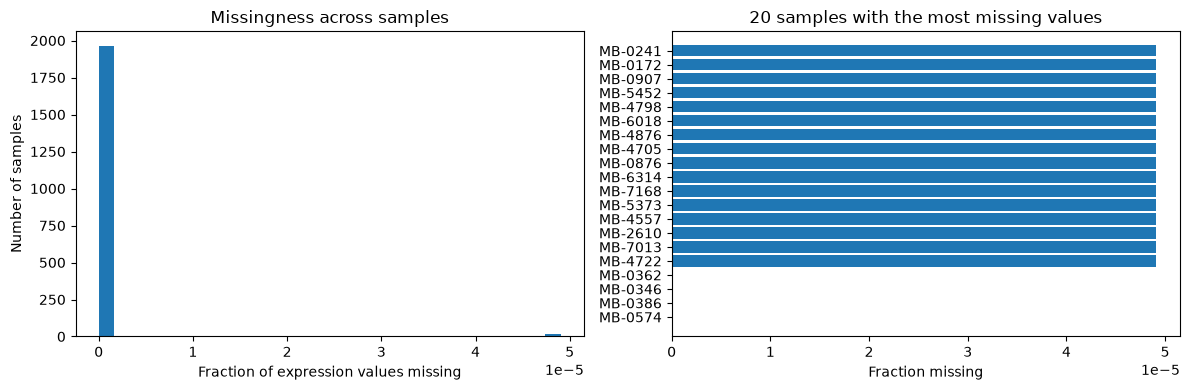

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(sample_missing, bins=30)
axes[0].set(
    xlabel="Fraction of expression values missing",
    ylabel="Number of samples",
    title="Missingness across samples"
)

worst_samples = sample_missing.nlargest(20).sort_values()
axes[1].barh(worst_samples.index.astype(str), worst_samples.values)
axes[1].set(
    xlabel="Fraction missing",
    title="20 samples with the most missing values"
)

plt.tight_layout()
plt.show()

Missingness by Gene

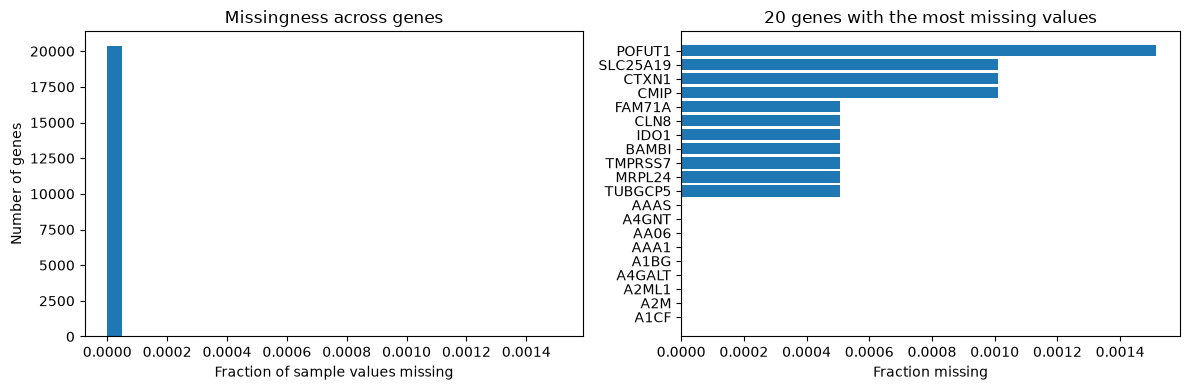

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(gene_missing, bins=30)
axes[0].set(
    xlabel="Fraction of sample values missing",
    ylabel="Number of genes",
    title="Missingness across genes"
)

worst_genes = gene_missing.nlargest(20).sort_values()
axes[1].barh(worst_genes.index.astype(str), worst_genes.values)
axes[1].set(
    xlabel="Fraction missing",
    title="20 genes with the most missing values"
)

plt.tight_layout()
plt.show()

Missingness Heatmap

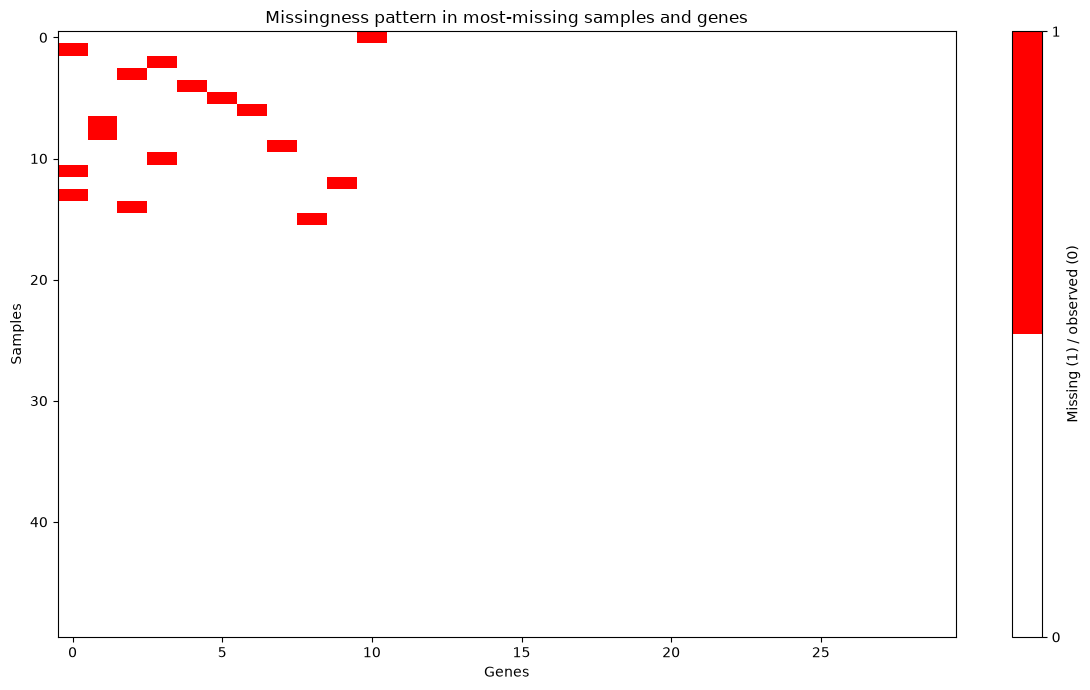

In [33]:
heat_samples = sample_missing.nlargest(min(50, len(sample_missing))).index
heat_genes = gene_missing.nlargest(min(30, len(gene_missing))).index
missing_matrix = expression.loc[heat_samples, heat_genes].isna()

plt.figure(figsize=(12, 7))
plt.imshow(
    missing_matrix,
    aspect="auto",
    interpolation="nearest",
    cmap=ListedColormap(["white", "red"]),
    vmin=0,
    vmax=1
)
plt.xlabel("Genes")
plt.ylabel("Samples")
plt.title("Missingness pattern in most-missing samples and genes")
plt.colorbar(ticks=[0, 1], label="Missing (1) / observed (0)")
plt.tight_layout()
plt.show()

PAM50 Label Availability and Subtype

In [34]:
[c for c in clinical.columns
 if any(term in c.upper() for term in ["SUBTYPE", "PAM", "CLAUDIN", "THREEGENE"])]

['CLAUDIN_SUBTYPE', 'THREEGENE', 'HISTOLOGICAL_SUBTYPE']

Subtype counts, including missing:
CLAUDIN_SUBTYPE
LumA           700
LumB           475
Her2           224
claudin-low    218
Basal          209
Normal         148
NC               6
Name: count, dtype: int64


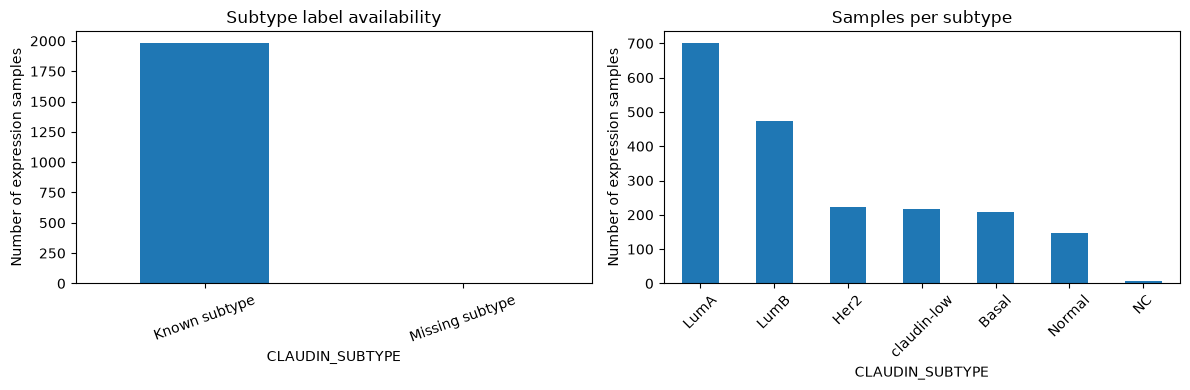

In [35]:
pam50_col = "CLAUDIN_SUBTYPE"

labels_by_sample = (
    clinical[["SAMPLE_ID", pam50_col]]
    .drop_duplicates("SAMPLE_ID")
)

label_data = expr_wide[["SAMPLE_ID"]].merge(
    labels_by_sample,
    on="SAMPLE_ID",
    how="left"
)

labels = label_data[pam50_col].fillna("").astype(str).str.strip()
missing_label = labels.eq("") | labels.str.upper().isin(
    ["NA", "N/A", "NAN", "NULL", "UNKNOWN", "NOT AVAILABLE"]
)

print("Subtype counts, including missing:")
print(labels.replace("", pd.NA).value_counts(dropna=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

status_counts = missing_label.map({
    False: "Known subtype",
    True: "Missing subtype"
}).value_counts().reindex(["Known subtype", "Missing subtype"], fill_value=0)

status_counts.plot.bar(ax=axes[0])
axes[0].set(ylabel="Number of expression samples", title="Subtype label availability")
axes[0].tick_params(axis="x", rotation=20)

labels[~missing_label].value_counts().plot.bar(ax=axes[1])
axes[1].set(ylabel="Number of expression samples", title="Samples per subtype")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

# **Investigating the Data Structure Using PCA and k-means**

In [8]:
import pandas as pd
import tarfile

archive_path = r"C:\Users\12063\Downloads\brca_metabric.tar.gz"


def read_tsv_from_archive(archive, filename, **kwargs):
    matches = [
        member for member in archive.getmembers()
        if member.isfile() and member.name.rsplit("/", 1)[-1] == filename
    ]

    if not matches:
        raise FileNotFoundError(f"{filename} was not found in the archive.")
    if len(matches) > 1:
        raise ValueError(f"Found multiple files named {filename} in the archive.")

    file_obj = archive.extractfile(matches[0])
    if file_obj is None:
        raise OSError(f"Could not read {filename} from the archive.")

    with file_obj:
        return pd.read_csv(file_obj, **kwargs)


with tarfile.open(archive_path, "r:gz") as archive:
    patients = read_tsv_from_archive(
        archive, "data_clinical_patient.txt", sep="\t", comment="#"
    )
    samples = read_tsv_from_archive(
        archive, "data_clinical_sample.txt", sep="\t", comment="#"
    )
    mut = read_tsv_from_archive(
        archive,
        "data_mutations.txt",
        sep="\t",
        comment="#",
        usecols=["Hugo_Symbol", "Tumor_Sample_Barcode"],
        low_memory=False
    )
    expr = read_tsv_from_archive(
        archive,
        "data_mrna_illumina_microarray_zscores_ref_diploid_samples.txt",
        sep="\t",
        index_col="Hugo_Symbol"
    )

# One row per sample, with patient-level information added.
clinical = patients.merge(
    samples, on="PATIENT_ID", validate="one_to_many"
)

if not clinical["SAMPLE_ID"].is_unique:
    raise ValueError("Clinical data has duplicate SAMPLE_ID values.")

# Create binary features for the 20 most frequently mutated genes.
mut["mutated"] = 1
top_mutation_genes = mut["Hugo_Symbol"].value_counts().head(20).index

mut_wide = (
    mut.pivot_table(
        index="Tumor_Sample_Barcode",
        columns="Hugo_Symbol",
        values="mutated",
        aggfunc="max",
        fill_value=0
    )[top_mutation_genes]
    .add_prefix("mut_")
    .rename_axis("SAMPLE_ID")
    .reset_index()
)

# Keep all expression genes here; your MAD filter selects up to 2,000 later.
expr = expr.drop(columns="Entrez_Gene_Id", errors="ignore")
expr = expr.groupby(level=0).mean()

expr_wide = (
    expr.T
    .add_prefix("expr_")
    .rename_axis("SAMPLE_ID")
    .reset_index()
)

# Combine the data by sample for a descriptive count.
wide = (
    clinical
    .merge(mut_wide, on="SAMPLE_ID", how="left", validate="one_to_one")
    .merge(expr_wide, on="SAMPLE_ID", how="left", validate="one_to_one")
)

mut_cols = [c for c in wide.columns if c.startswith("mut_")]
expr_cols = [c for c in wide.columns if c.startswith("expr_")]
clinical_cols = [
    c for c in wide.columns
    if c not in mut_cols + expr_cols + ["PATIENT_ID", "SAMPLE_ID"]
]
feature_cols = clinical_cols + mut_cols + expr_cols

print(f"Samples (rows): {len(wide):,}")
print(f"Clinical columns: {len(clinical_cols):,}")
print(f"Mutation columns: {len(mut_cols):,}")
print(f"Expression columns before filtering: {len(expr_cols):,}")
print(f"Total possible feature columns, excluding IDs: {len(feature_cols):,}")

# Number of non-missing feature values available for each sample.
features_present = wide[feature_cols].notna().sum(axis=1)
print("\nNon-missing feature values per sample:")
print(features_present.describe().round(1))

Samples (rows): 2,509
Clinical columns: 34
Mutation columns: 20
Expression columns before filtering: 20,385
Total possible feature columns, excluding IDs: 20,439

Non-missing feature values per sample:
count     2509.0
mean     16135.6
std       8323.9
min          8.0
25%      20419.0
50%      20438.0
75%      20439.0
max      20439.0
dtype: float64


In [9]:
import warnings
import numpy as np
from sklearn.base import BaseEstimator, TransformerMixin

# Gene selection settings
MAX_GENE_MISSING = 0.10   # Exclude genes missing in more than 10% of samples
N_TOP_MAD_GENES = 2000    # Keep up to 2,000 genes with the highest MAD


def nan_mad(A):
    """Calculate each gene's median absolute deviation, ignoring missing values."""
    A = np.asarray(A, dtype=float)
    out = np.empty(A.shape[1])
    has_nan = np.isnan(A).any(axis=0)

    full = A[:, ~has_nan]
    out[~has_nan] = np.median(
        np.abs(full - np.median(full, axis=0)),
        axis=0
    )

    if has_nan.any():
        part = A[:, has_nan]
        out[has_nan] = np.nanmedian(
            np.abs(part - np.nanmedian(part, axis=0)),
            axis=0
        )

    return out


class MADGeneFilter(TransformerMixin, BaseEstimator):
    """Filter genes by missingness and variability, then keep the highest-MAD genes."""

    def __init__(self, max_missing=0.10, n_genes=2000):
        self.max_missing = max_missing
        self.n_genes = n_genes

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=float)
        self.n_features_in_ = X.shape[1]

        # Step 1: exclude genes with too much missing data.
        passes_missing = np.isnan(X).mean(axis=0) <= self.max_missing

        # Step 2: exclude genes with no variation.
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", category=RuntimeWarning)
            spread = np.nanmax(X, axis=0) - np.nanmin(X, axis=0)

        passes_variance = passes_missing & (spread > 0)

        # Step 3: rank remaining genes by median absolute deviation.
        self.mad_ = np.full(X.shape[1], -np.inf)
        self.mad_[passes_variance] = nan_mad(X[:, passes_variance])
        ranking = np.argsort(-self.mad_, kind="stable")

        # Step 4: keep up to the requested number of genes.
        n_keep = min(self.n_genes, int(passes_variance.sum()))
        self.keep_idx_ = np.sort(ranking[:n_keep])

        self.n_genes_start_ = X.shape[1]
        self.n_after_step1_ = int(passes_missing.sum())
        self.n_after_step2_ = int(passes_variance.sum())
        self.mad_cutoff_ = (
            float(self.mad_[ranking[n_keep - 1]]) if n_keep else float("nan")
        )

        return self

    def transform(self, X):
        return np.asarray(X, dtype=float)[:, self.keep_idx_]

    def get_feature_names_out(self, input_features=None):
        if input_features is None:
            raise ValueError("Pass input gene names to get_feature_names_out().")
        return np.asarray(input_features, dtype=object)[self.keep_idx_]

In [10]:
# Select up to 2,000 expression genes using the MAD filter.
X_expr = expr_wide.set_index("SAMPLE_ID").copy()
X_expr.columns = X_expr.columns.str.replace(r"^expr_", "", regex=True)

gene_filter = MADGeneFilter(
    max_missing=MAX_GENE_MISSING,
    n_genes=N_TOP_MAD_GENES
)

selected_array = gene_filter.fit_transform(X_expr)
selected_gene_names = gene_filter.get_feature_names_out(X_expr.columns)

expr_selected = pd.DataFrame(
    selected_array,
    index=X_expr.index,
    columns=selected_gene_names
)

print(f"Genes at start: {gene_filter.n_features_in_}")
print(f"After missingness filter: {gene_filter.n_after_step1_}")
print(f"After zero-variance filter: {gene_filter.n_after_step2_}")
print(f"Genes selected: {expr_selected.shape[1]}")
print(f"Samples: {expr_selected.shape[0]}")

Genes at start: 20385
After missingness filter: 20385
After zero-variance filter: 20385
Genes selected: 2000
Samples: 1980


**Principal Components Analysis**

In [39]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


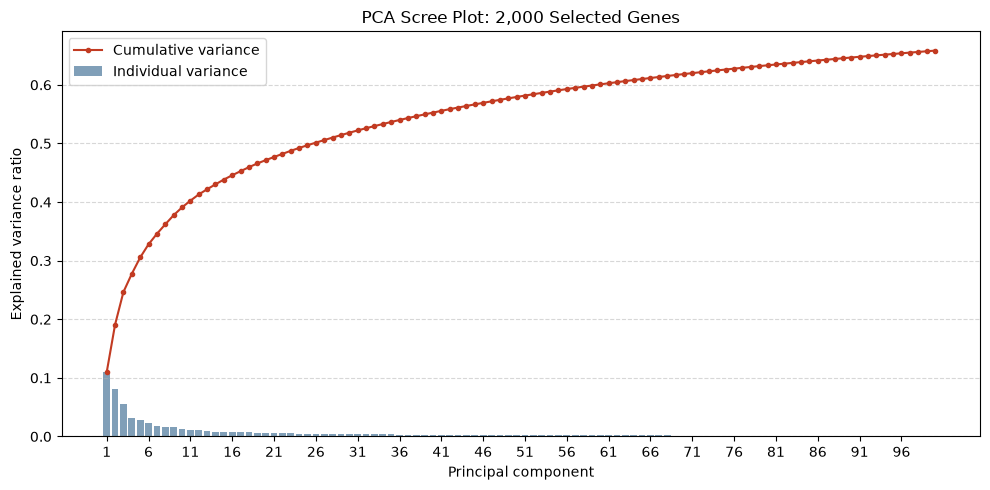

Samples: 1,980
Selected expression genes: 2,000
Explained variance by PC1: 10.97%
Explained variance by PC2: 8.12%
Total explained variance by PC1 & PC2: 19.09%
First 5 PCs: 30.54% variance
First 10 PCs: 39.09% variance
First 20 PCs: 47.15% variance
First 30 PCs: 51.83% variance
First 50 PCs: 57.93% variance
First 60 PCs: 60.08% variance
First 70 PCs: 61.84% variance
First 80 PCs: 63.34% variance
First 90 PCs: 64.66% variance
First 100 PCs: 65.84% variance


In [11]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# Use the genes selected by MADGeneFilter; the index contains sample IDs.
expr_features = expr_selected.copy()
samples_with_expr = expr_features.index

if expr_features.shape[1] == 0:
    raise ValueError("expr_selected has no selected genes.")

# Impute missing values per gene, then standardize.
expr_imputed = SimpleImputer(strategy="median").fit_transform(expr_features)
expr_scaled = StandardScaler().fit_transform(expr_imputed)

# Calculate up to 100 PCs for the scree plot.
n_components = min(100, expr_scaled.shape[0], expr_scaled.shape[1])
if n_components < 2:
    raise ValueError("At least two samples and two selected genes are needed for PCA.")

pca = PCA(
    n_components=n_components,
    svd_solver="randomized",
    random_state=0
)
pca_transformed = pca.fit_transform(expr_scaled)

var_ratio = pca.explained_variance_ratio_
cum_var_ratio = np.cumsum(var_ratio)

pcs = np.arange(1, n_components + 1)
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(pcs, var_ratio, alpha=0.6, label="Individual variance", color="#2c5f8a")
ax.plot(
    pcs, cum_var_ratio,
    marker="o", markersize=3,
    label="Cumulative variance", color="#c23b22"
)

ax.set_xlabel("Principal component")
ax.set_ylabel("Explained variance ratio")
ax.set_title(f"PCA Scree Plot: {expr_features.shape[1]:,} Selected Genes")
ax.set_xticks(pcs[::5])
ax.grid(True, axis="y", linestyle="--", alpha=0.5)
ax.legend()
plt.tight_layout()
plt.show()

print(f"Samples: {expr_scaled.shape[0]:,}")
print(f"Selected expression genes: {expr_scaled.shape[1]:,}")
print(f"Explained variance by PC1: {var_ratio[0]:.2%}")
print(f"Explained variance by PC2: {var_ratio[1]:.2%}")
print(f"Total explained variance by PC1 & PC2: {cum_var_ratio[1]:.2%}")

for n in [5, 10, 20, 30, 50, 60, 70, 80, 90, 100]:
    if n <= n_components:
        print(f"First {n} PCs: {cum_var_ratio[n - 1]:.2%} variance")

In [41]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


PCA using 60 PCs and k-means using prespecified 5 clusters (to represent the 5 primary subtypes)

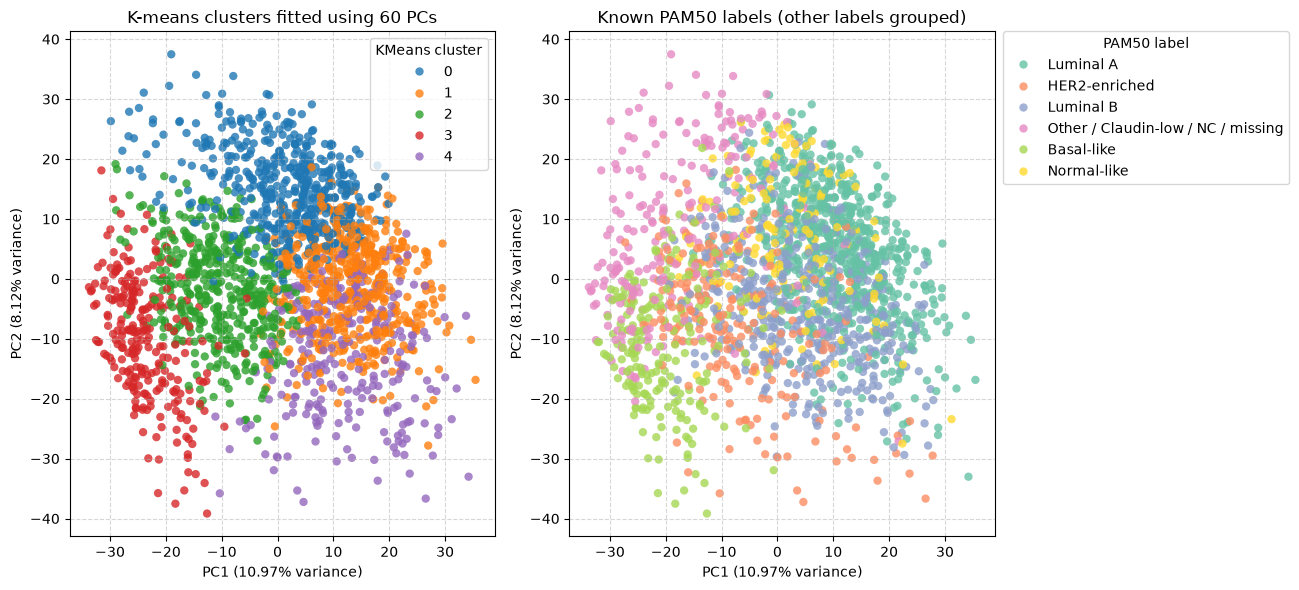

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

n_pcs = 60 # numbers of PCs to use for clustering
n_clusters = 5 # number of kmeans clusters

if pca_transformed.shape[1] < n_pcs:
    raise ValueError(f"PCA must provide at least {n_pcs} components.")

# Fit K-means on the first n_pcs PCs, without subtype labels.
cluster_ids = KMeans(
    n_clusters=n_clusters,
    n_init=20,
    random_state=42
).fit_predict(pca_transformed[:, :n_pcs])

# Align labels to the expression samples.
subtypes = (
    clinical[["SAMPLE_ID", "CLAUDIN_SUBTYPE"]]
    .drop_duplicates("SAMPLE_ID")
    .set_index("SAMPLE_ID")["CLAUDIN_SUBTYPE"]
)
raw_subtypes = subtypes.reindex(samples_with_expr).astype("string").str.strip()

# Map only the five standard PAM50 groups.
pam50_map = {
    "LUMA": "Luminal A",
    "LUMINAL A": "Luminal A",
    "LUMB": "Luminal B",
    "LUMINAL B": "Luminal B",
    "HER2": "HER2-enriched",
    "HER2-ENRICHED": "HER2-enriched",
    "HER2 ENRICHED": "HER2-enriched",
    "BASAL": "Basal-like",
    "BASAL-LIKE": "Basal-like",
    "NORMAL": "Normal-like",
    "NORMAL-LIKE": "Normal-like",
}
pam50_labels = raw_subtypes.str.upper().map(pam50_map)

pca_df = pd.DataFrame(
    pca_transformed[:, :2],
    columns=["PC1", "PC2"],
    index=samples_with_expr
)
pca_df["KMeans cluster"] = cluster_ids.astype(str)
pca_df["PAM50"] = pam50_labels
pca_df["PAM50 plot label"] = pam50_labels.fillna(
    "Other / Claudin-low / NC / missing"
)

# Visualize cluster assignments and known subtype labels on the first two PCs.
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(
    data=pca_df, x="PC1", y="PC2", hue="KMeans cluster",
    hue_order=[str(i) for i in range(n_clusters)],
    palette="tab10", alpha=0.8, edgecolor="none", ax=axes[0]
)
axes[0].set_title(f"K-means clusters fitted using {n_pcs} PCs")

sns.scatterplot(
    data=pca_df, x="PC1", y="PC2", hue="PAM50 plot label",
    palette="Set2", alpha=0.8, edgecolor="none", ax=axes[1]
)
axes[1].set_title("Known PAM50 labels (other labels grouped)")

# Place the right plot's legend outside the plotting area.
axes[1].legend(
    title="PAM50 label",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
    borderaxespad=0
)

for ax in axes:
    ax.set_xlabel(f"PC1 ({var_ratio[0]:.2%} variance)")
    ax.set_ylabel(f"PC2 ({var_ratio[1]:.2%} variance)")
    ax.grid(True, linestyle="--", alpha=0.5)

# Reserve room on the right so the legend isn't clipped.
fig.tight_layout(rect=[0, 0, 0.82, 1])
plt.show()

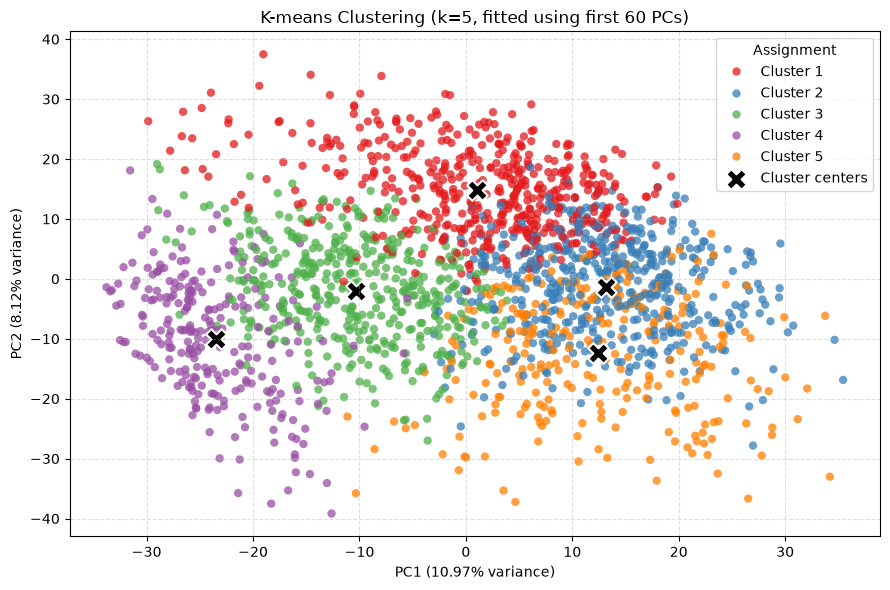

Samples per cluster:
Cluster
Cluster 1    507
Cluster 2    502
Cluster 3    438
Cluster 4    257
Cluster 5    276
Name: count, dtype: int64


In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

n_pcs = 60

if pca_transformed.shape[1] < n_pcs:
    raise ValueError(f"PCA must provide at least {n_pcs} components.")

# Fit K-means on the first 60 PCs.
kmeans_5 = KMeans(
    n_clusters=5,
    n_init=20,
    random_state=42
)
cluster_ids_5 = kmeans_5.fit_predict(pca_transformed[:, :n_pcs])

# Prepare the first two PCs for plotting.
cluster_plot_5 = pd.DataFrame(
    pca_transformed[:, :2],
    columns=["PC1", "PC2"],
    index=samples_with_expr
)
cluster_plot_5["Cluster"] = pd.Series(
    cluster_ids_5, index=samples_with_expr
).map({i: f"Cluster {i + 1}" for i in range(5)})

plt.figure(figsize=(9, 6))
ax = sns.scatterplot(
    data=cluster_plot_5,
    x="PC1",
    y="PC2",
    hue="Cluster",
    hue_order=[f"Cluster {i}" for i in range(1, 6)],
    palette="Set1",
    alpha=0.75,
    edgecolor="none"
)

# Show the cluster centers projected onto PC1 and PC2.
centers = kmeans_5.cluster_centers_[:, :2]
ax.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="X",
    s=220,
    c="black",
    edgecolor="white",
    linewidth=1.5,
    label="Cluster centers"
)

ax.set_title(f"K-means Clustering (k=5, fitted using first {n_pcs} PCs)")
ax.set_xlabel(f"PC1 ({var_ratio[0]:.2%} variance)")
ax.set_ylabel(f"PC2 ({var_ratio[1]:.2%} variance)")
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(title="Assignment")
plt.tight_layout()
plt.show()

print("Samples per cluster:")
print(cluster_plot_5["Cluster"].value_counts().sort_index())

In [14]:
# Agreement with PAM50, only for patients with one of the five standard PAM50 labels
known_pam50 = pca_df["PAM50"].notna()
print(f"Samples included in PAM50 evaluation: {known_pam50.sum()}")
print("ARI:", round(adjusted_rand_score(pca_df.loc[known_pam50, "PAM50"],
                                        pca_df.loc[known_pam50, "KMeans cluster"]), 3))
print("NMI:", round(normalized_mutual_info_score(pca_df.loc[known_pam50, "PAM50"],
                                                 pca_df.loc[known_pam50, "KMeans cluster"]), 3))

Samples included in PAM50 evaluation: 1756
ARI: 0.206
NMI: 0.307


Determining k from silhoutte scores -> k=2

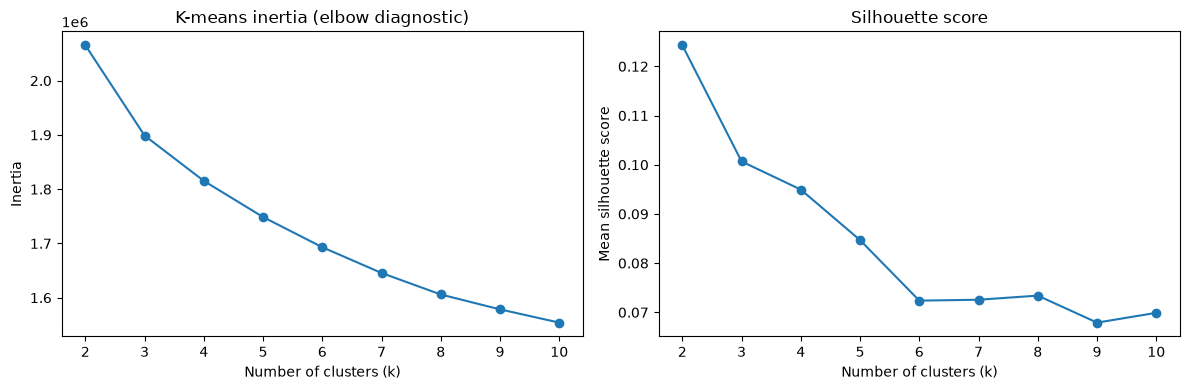

,inertia,silhouette,smallest_cluster
k,,,
2,2065357.126,0.124,770
3,1898850.893,0.101,589
4,1815301.241,0.095,303
5,1748654.477,0.085,257
6,1693034.362,0.072,163
7,1645562.793,0.073,136
8,1605922.068,0.073,131
9,1578483.378,0.068,117
10,1554071.572,0.070,23


Highest silhouette score: k=2


In [15]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

n_pcs = 60
Z = pca_transformed[:, :n_pcs]

if Z.shape[1] < n_pcs:
    raise ValueError(f"PCA must provide at least {n_pcs} components.")

rows = []
models = {}

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        n_init=20,
        random_state=42
    )
    cluster_ids = model.fit_predict(Z)
    models[k] = model

    score = silhouette_score(
        Z,
        cluster_ids,
        sample_size=min(1000, len(Z)),
        random_state=42
    )

    sizes = pd.Series(cluster_ids).value_counts()
    rows.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette": score,
        "smallest_cluster": sizes.min()
    })

k_table = pd.DataFrame(rows).set_index("k")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

k_table["inertia"].plot(
    marker="o", ax=axes[0], title="K-means inertia (elbow diagnostic)"
)
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")

k_table["silhouette"].plot(
    marker="o", ax=axes[1], title="Silhouette score"
)
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Mean silhouette score")

plt.tight_layout()
plt.show()

display(k_table.round(3))

best_k = int(k_table["silhouette"].idxmax())
print(f"Highest silhouette score: k={best_k}")

In [16]:
from sklearn.metrics import adjusted_rand_score as ari

k_final = 2  # set from step 1
base = KMeans(n_clusters=k_final, n_init=20, random_state=42).fit_predict(Z)
rng = np.random.default_rng(0)
stab = [ari(base, KMeans(n_clusters=k_final, n_init=20, random_state=b)
                  .fit(Z[rng.choice(len(Z), int(0.8 * len(Z)), replace=False)]).predict(Z))
        for b in range(20)]
print(f"Stability ARI over 20 subsamples: mean {np.mean(stab):.2f}, lowest {np.min(stab):.2f}")

Stability ARI over 20 subsamples: mean 0.97, lowest 0.90


col_0,0,1
CLAUDIN_SUBTYPE,,
Basal,208,1
Her2,174,50
LumA,24,676
LumB,133,342
NC,0,6
Normal,35,113
claudin-low,196,22


col_0,0,1
ER_STATUS,,
Negative,455,19
Positive,315,1191


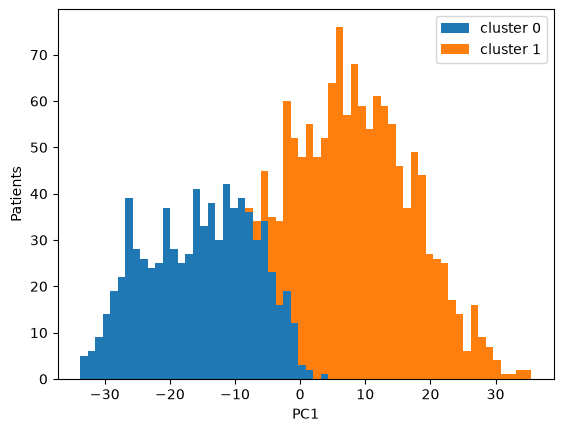

In [17]:
k2 = base  # the k = 2 solution
er = clinical.drop_duplicates("SAMPLE_ID").set_index("SAMPLE_ID")["ER_STATUS"].reindex(pca_df.index)
display(pd.crosstab(raw_subtypes.fillna("missing"), k2))   # which subtypes fall in each cluster
display(pd.crosstab(er, k2))                               # ER status by cluster

plt.hist([Z[k2 == c, 0] for c in (0, 1)], bins=60, stacked=True, label=["cluster 0", "cluster 1"])
plt.xlabel("PC1"); plt.ylabel("Patients"); plt.legend(); plt.show()

k-means Clustering using k=2

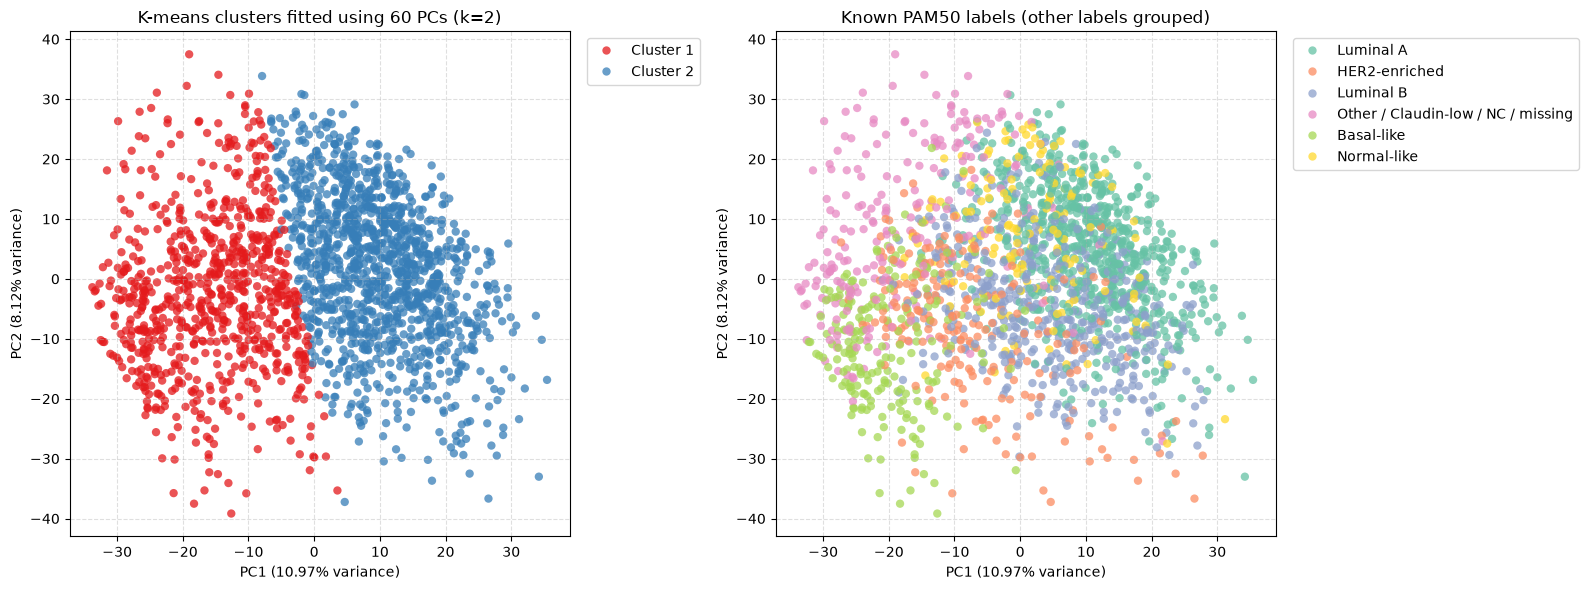

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

n_pcs = 60

if pca_transformed.shape[1] < n_pcs:
    raise ValueError(f"PCA must provide at least {n_pcs} components.")

# Fit K-means using expression PCs only; subtype labels are not used.
cluster_ids = KMeans(
    n_clusters=2,
    n_init=20,
    random_state=42
).fit_predict(pca_transformed[:, :n_pcs])

# Align subtype annotations to the expression sample order.
subtype_by_sample = (
    clinical[["SAMPLE_ID", "CLAUDIN_SUBTYPE"]]
    .drop_duplicates("SAMPLE_ID")
    .set_index("SAMPLE_ID")["CLAUDIN_SUBTYPE"]
)
raw_subtypes = (
    subtype_by_sample.reindex(samples_with_expr)
    .astype("string")
    .str.strip()
    .str.upper()
)

pam50_map = {
    "LUMA": "Luminal A",
    "LUMINAL A": "Luminal A",
    "LUMB": "Luminal B",
    "LUMINAL B": "Luminal B",
    "HER2": "HER2-enriched",
    "HER2-ENRICHED": "HER2-enriched",
    "HER2 ENRICHED": "HER2-enriched",
    "BASAL": "Basal-like",
    "BASAL-LIKE": "Basal-like",
    "NORMAL": "Normal-like",
    "NORMAL-LIKE": "Normal-like",
}

other_label = "Other / Claudin-low / NC / missing"
label_order = [
    "Luminal A",
    "HER2-enriched",
    "Luminal B",
    other_label,
    "Basal-like",
    "Normal-like",
]

mapped_labels = raw_subtypes.map(pam50_map).fillna(other_label)

plot_df = pd.DataFrame(
    pca_transformed[:, :2],
    columns=["PC1", "PC2"],
    index=samples_with_expr
)
plot_df["KMeans cluster"] = [
    f"Cluster {cluster_id + 1}" for cluster_id in cluster_ids
]
plot_df["PAM50 plot label"] = pd.Categorical(
    mapped_labels,
    categories=label_order,
    ordered=True
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="KMeans cluster",
    hue_order=["Cluster 1", "Cluster 2"],
    palette="Set1",
    alpha=0.75,
    edgecolor="none",
    ax=axes[0]
)
axes[0].set_title(f"K-means clusters fitted using {n_pcs} PCs (k=2)")

sns.scatterplot(
    data=plot_df,
    x="PC1",
    y="PC2",
    hue="PAM50 plot label",
    hue_order=label_order,
    palette="Set2",
    alpha=0.75,
    edgecolor="none",
    ax=axes[1]
)
axes[1].set_title("Known PAM50 labels (other labels grouped)")

for ax in axes:
    ax.set_xlabel(f"PC1 ({var_ratio[0]:.2%} variance)")
    ax.set_ylabel(f"PC2 ({var_ratio[1]:.2%} variance)")
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.legend(title=None, bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

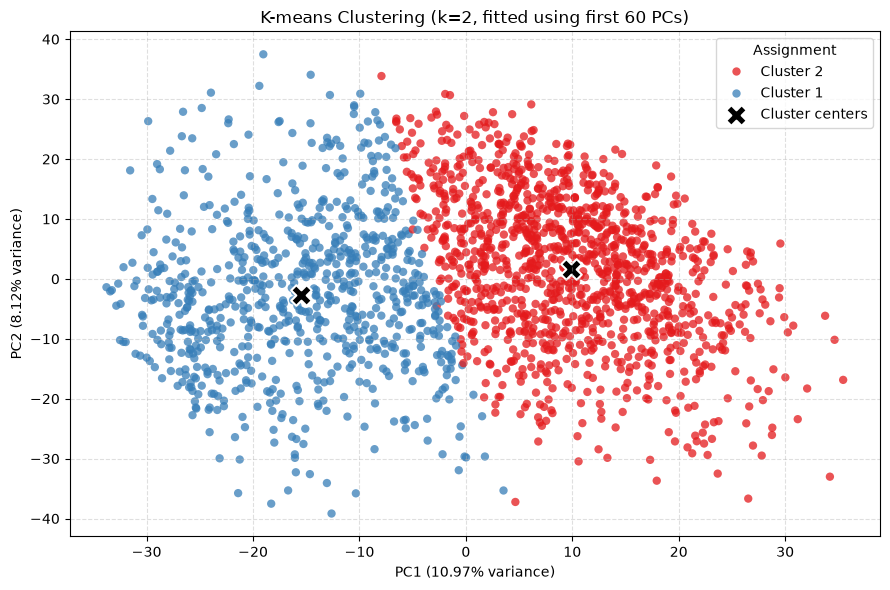

Samples per cluster:
Cluster
Cluster 2    1210
Cluster 1     770
Name: count, dtype: int64


In [19]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

n_pcs = 60

if pca_transformed.shape[1] < n_pcs:
    raise ValueError(f"PCA must provide at least {n_pcs} components.")

# Fit K-means on the first 60 PCs.
kmeans_2 = KMeans(
    n_clusters=2,
    n_init=20,
    random_state=42
)
cluster_ids = kmeans_2.fit_predict(pca_transformed[:, :n_pcs])

# Prepare the first two PCs for plotting.
cluster_plot = pd.DataFrame(
    pca_transformed[:, :2],
    columns=["PC1", "PC2"],
    index=samples_with_expr
)
cluster_plot["Cluster"] = pd.Series(
    cluster_ids, index=samples_with_expr
).map({0: "Cluster 1", 1: "Cluster 2"})

# Plot cluster assignments.
plt.figure(figsize=(9, 6))
ax = sns.scatterplot(
    data=cluster_plot,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="Set1",
    alpha=0.75,
    edgecolor="none"
)

# Show the cluster centers projected onto PC1 and PC2.
centers = kmeans_2.cluster_centers_[:, :2]
ax.scatter(
    centers[:, 0],
    centers[:, 1],
    marker="X",
    s=220,
    c="black",
    edgecolor="white",
    linewidth=1.5,
    label="Cluster centers"
)

ax.set_title(f"K-means Clustering (k=2, fitted using first {n_pcs} PCs)")
ax.set_xlabel(f"PC1 ({var_ratio[0]:.2%} variance)")
ax.set_ylabel(f"PC2 ({var_ratio[1]:.2%} variance)")
ax.grid(True, linestyle="--", alpha=0.4)
ax.legend(title="Assignment")
plt.tight_layout()
plt.show()

print("Samples per cluster:")
print(cluster_plot["Cluster"].value_counts())